An AI project by Warsh.


The main objective of this project is to create the closest program that I can easily recoginze market data of any card / product accurately.


In [ ]:
import requests
import pandas as pd

In [ ]:
url = "https://api.pokemontcg.io/v2/cards?page=1&pageSize=10"

response = requests.get(url)

print(response.status_code)

502


In [ ]:
df = pd.read_csv("/content/SVScarletAndViolet151ProductsAndPrices.csv")

df.head()

,productId,name,cleanName,imageUrl,categoryId,groupId,url,modifiedOn,imageCount,extCardText,...,extRarity,extCardType,extHP,extStage,extAttack1,extAttack2,extWeakness,extResistance,extRetreatCost,extUPC
0,501999,151 Pokemon Center Elite Trainer Box (Exclusive),151 Pokemon Center Elite Trainer Box Exclusive,https://tcgplayer-cdn.tcgplayer.com/product/50...,3,23237,https://cpt.tcgcsv.com/_P06,2026-02-19T18:47:19.317,1,"Team up with Bulbasaur, Charmander, and Squirt...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,502000,151 Booster Bundle,151 Booster Bundle,https://tcgplayer-cdn.tcgplayer.com/product/50...,3,23237,https://cpt.tcgcsv.com/0Q06,2026-02-19T18:45:42.91,1,"Team up with Bulbasaur, Charmander, and Squirt...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,502001,151 Poster Collection,151 Poster Collection,https://tcgplayer-cdn.tcgplayer.com/product/50...,3,23237,https://cpt.tcgcsv.com/2Q06,2023-09-22T04:03:23.64,1,Your Very Own Pokémon Legend Unfolds!\r\n<br>A...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,502002,151 Poster Collection Case,151 Poster Collection Case,https://tcgplayer-cdn.tcgplayer.com/product/50...,3,23237,https://cpt.tcgcsv.com/3Q06,2023-09-22T04:03:23.64,1,This case contains 6 copies of 151 Poster Coll...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,502003,151 Binder Collection Case,151 Binder Collection Case,https://tcgplayer-cdn.tcgplayer.com/product/50...,3,23237,https://cpt.tcgcsv.com/5Q06,2026-02-19T18:44:50.47,1,How Many Pages Can You Fill?\r\n<br>Just like ...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

df.columns.tolist()

Rows: 402
Columns: 27


['productId',
 'name',
 'cleanName',
 'imageUrl',
 'categoryId',
 'groupId',
 'url',
 'modifiedOn',
 'imageCount',
 'extCardText',
 'lowPrice',
 'midPrice',
 'highPrice',
 'marketPrice',
 'directLowPrice',
 'subTypeName',
 'extNumber',
 'extRarity',
 'extCardType',
 'extHP',
 'extStage',
 'extAttack1',
 'extAttack2',
 'extWeakness',
 'extResistance',
 'extRetreatCost',
 'extUPC']

In [ ]:
raw_df = df.copy()

print("Raw dataset saved in memory.")
print(raw_df.shape)

Raw dataset saved in memory.
(402, 27)


In [ ]:
df[["name", "marketPrice", "extRarity", "extNumber", "extCardType"]].head(20)

,name,marketPrice,extRarity,extNumber,extCardType
0,151 Pokemon Center Elite Trainer Box (Exclusive),1275.77,NaN,NaN,NaN
1,151 Booster Bundle,159.73,NaN,NaN,NaN
2,151 Poster Collection,85.67,NaN,NaN,NaN
3,151 Poster Collection Case,574.96,NaN,NaN,NaN
4,151 Binder Collection Case,NaN,NaN,NaN,NaN
5,151 Binder Collection,229.80,NaN,NaN,NaN
6,151 Ultra-Premium Collection,854.37,NaN,NaN,NaN
7,151: Alakazam ex Collection,118.31,NaN,NaN,NaN
8,151: Zapdos ex Collection,121.21,NaN,NaN,NaN
9,151 Mini Tin Display,540.95,NaN,NaN,NaN


In [ ]:
df["extRarity"].value_counts(dropna=False)

,count
extRarity,
Common,132
Uncommon,124
Rare,50
NaN,34
Illustration Rare,16
Ultra Rare,16
Double Rare,13
Special Illustration Rare,7
Code Card,7


In [ ]:
cards_df = df[df["extNumber"].notna()].copy()

print("Total products:", len(df))
print("Individual cards:", len(cards_df))

Total products: 402
Individual cards: 361


In [ ]:
cards_df[["name", "marketPrice", "extRarity", "extNumber", "extCardType"]].head(20)

,name,marketPrice,extRarity,extNumber,extCardType
10,Squirtle - 007/165,0.39,Common,007/165,Water
11,Squirtle - 007/165,0.28,Common,007/165,Water
12,Squirtle - 170/165,89.91,Illustration Rare,170/165,Water
13,Wartortle - 008/165,0.29,Uncommon,008/165,Water
14,Wartortle - 008/165,0.57,Uncommon,008/165,Water
15,Blastoise ex - 009/165,2.22,Double Rare,009/165,Water
16,Bulbasaur - 001/165,0.39,Common,001/165,Grass
17,Bulbasaur - 001/165,0.28,Common,001/165,Grass
18,Ivysaur - 002/165,0.32,Uncommon,002/165,Grass
19,Ivysaur - 002/165,0.56,Uncommon,002/165,Grass


In [ ]:
print("Cards with market price:", cards_df["marketPrice"].notna().sum())
print("Cards without market price:", cards_df["marketPrice"].isna().sum())

Cards with market price: 361
Cards without market price: 0


In [ ]:
cards_df["marketPrice"].describe()

,marketPrice
count,361.000000
mean,5.506925
std,24.109532
min,0.090000
25%,0.210000
50%,0.290000
75%,1.330000
max,353.460000


In [ ]:
cards_df[cards_df["name"] == "Squirtle - 007/165"][
    ["productId", "name", "marketPrice", "subTypeName", "extNumber", "extRarity"]
]

,productId,name,marketPrice,subTypeName,extNumber,extRarity
10,502548,Squirtle - 007/165,0.39,Reverse Holofoil,007/165,Common
11,502548,Squirtle - 007/165,0.28,Normal,007/165,Common


In [ ]:
duplicate_summary = (
    cards_df.groupby("productId")
    .agg(
        records=("productId", "size"),
        name=("name", "first"),
        variants=("subTypeName", lambda x: ", ".join(x.dropna().astype(str))),
        prices=("marketPrice", lambda x: ", ".join(x.astype(str)))
    )
    .query("records > 1")
    .sort_values("records", ascending=False)
)

duplicate_summary.head(20)

,records,name,variants,prices
productId,,,,
502548,2,Squirtle - 007/165,"Reverse Holofoil, Normal","0.39, 0.28"
502550,2,Wartortle - 008/165,"Normal, Reverse Holofoil","0.29, 0.57"
502552,2,Bulbasaur - 001/165,"Reverse Holofoil, Normal","0.39, 0.28"
502553,2,Ivysaur - 002/165,"Normal, Reverse Holofoil","0.32, 0.56"
502555,2,Charmander - 004/165,"Reverse Holofoil, Normal","0.35, 0.28"
502557,2,Charmeleon - 005/165,"Reverse Holofoil, Normal","0.36, 0.3"
502559,2,Caterpie - 010/165,"Reverse Holofoil, Normal","0.37, 0.22"
502560,2,Metapod,"Normal, Reverse Holofoil","0.22, 3.01"
502561,2,Butterfree,"Reverse Holofoil, Normal","0.28, 0.23"


In [ ]:
cards_clean = cards_df.copy()

# Make sure market price is numeric
cards_clean["marketPrice"] = pd.to_numeric(
    cards_clean["marketPrice"],
    errors="coerce"
)

# Clean variant names
cards_clean["subTypeName"] = cards_clean["subTypeName"].fillna("Unknown")

# Remove exact duplicate rows only
cards_clean = cards_clean.drop_duplicates()

print("Original card records:", len(cards_df))
print("After removing exact duplicates:", len(cards_clean))

Original card records: 361
After removing exact duplicates: 361


In [ ]:
cards_clean["subTypeName"].value_counts()

,count
subTypeName,
Reverse Holofoil,153
Normal,129
Holofoil,79


In [ ]:
cards_clean.groupby("subTypeName")["marketPrice"].agg(
    ["count", "mean", "median", "min", "max"]
).sort_values("median", ascending=False)

,count,mean,median,min,max
subTypeName,,,,,
Holofoil,79,22.767342,4.72,0.23,353.46
Reverse Holofoil,153,0.925752,0.37,0.21,8.89
Normal,129,0.370078,0.18,0.09,22.86


In [ ]:
rarity_analysis = (
    cards_clean
    .groupby("extRarity")["marketPrice"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median", ascending=False)
)

rarity_analysis

,count,mean,median,min,max
extRarity,,,,,
Special Illustration Rare,7,112.145714,86.460,14.85,353.46
Illustration Rare,16,46.694375,44.370,13.22,93.05
Ultra Rare,16,11.617500,7.390,2.99,39.32
Hyper Rare,3,11.510000,4.350,2.37,27.81
Double Rare,13,4.153846,1.650,1.00,22.86
Rare,50,1.270800,0.935,0.23,8.89
Uncommon,124,0.505323,0.270,0.09,5.35
Common,132,0.418636,0.260,0.09,3.11


In [ ]:
rarity_variant = (
    cards_clean
    .groupby(["extRarity", "subTypeName"])["marketPrice"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
)

rarity_variant


,,count,mean,median
extRarity,subTypeName,,,
Special Illustration Rare,Holofoil,7,112.145714,86.460
Illustration Rare,Holofoil,16,46.694375,44.370
Double Rare,Normal,1,22.860000,22.860
Ultra Rare,Holofoil,16,11.617500,7.390
Hyper Rare,Holofoil,3,11.510000,4.350
Double Rare,Holofoil,12,2.595000,1.610
Rare,Reverse Holofoil,25,1.944000,1.400
Uncommon,Reverse Holofoil,62,0.811129,0.345
Rare,Holofoil,25,0.597600,0.310


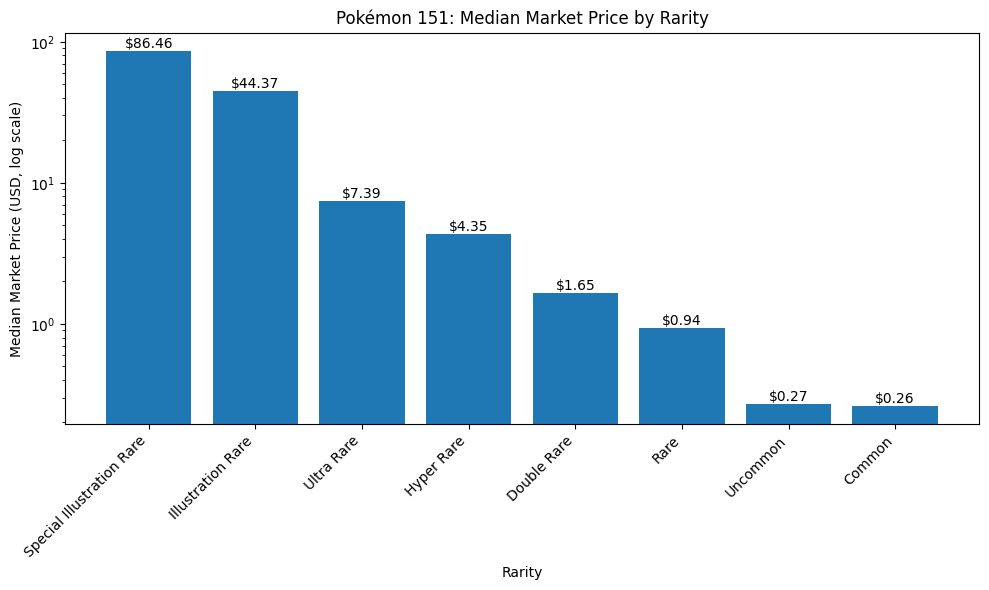

In [ ]:
import matplotlib.pyplot as plt

# Calculate median price by rarity
rarity_median = (
    cards_clean
    .groupby("extRarity")["marketPrice"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(rarity_median.index, rarity_median.values)

plt.yscale("log")
plt.xlabel("Rarity")
plt.ylabel("Median Market Price (USD, log scale)")
plt.title("Pokémon 151: Median Market Price by Rarity")
plt.xticks(rotation=45, ha="right")

# Add price labels
for bar, value in zip(bars, rarity_median.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"${value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Most valuable cards

In [ ]:
top_cards = (
    cards_clean[
        [
            "name",
            "marketPrice",
            "extRarity",
            "subTypeName",
            "extNumber"
        ]
    ]
    .sort_values("marketPrice", ascending=False)
)

top_cards.head(20)
top_10 = top_cards.head(10).copy()

top_10

,name,marketPrice,extRarity,subTypeName,extNumber
366,Charizard ex - 199/165,353.46,Special Illustration Rare,Holofoil,199/165
367,Blastoise ex - 200/165,131.61,Special Illustration Rare,Holofoil,200/165
365,Venusaur ex - 198/165,109.57,Special Illustration Rare,Holofoil,198/165
23,Charmander - 168/165,93.05,Illustration Rare,Holofoil,168/165
12,Squirtle - 170/165,89.91,Illustration Rare,Holofoil,170/165
369,Zapdos ex - 202/165,86.46,Special Illustration Rare,Holofoil,202/165
58,Pikachu - 173/165,79.69,Illustration Rare,Holofoil,173/165
335,Bulbasaur - 166/165,78.60,Illustration Rare,Holofoil,166/165
368,Alakazam ex - 201/165,73.85,Special Illustration Rare,Holofoil,201/165
356,Psyduck - 175/165,61.14,Illustration Rare,Holofoil,175/165


Calculation of concentrated market

In [ ]:
total_market_value = cards_clean["marketPrice"].sum()

top_10_value = top_10["marketPrice"].sum()

percentage = (top_10_value / total_market_value) * 100

print(f"Total card market value: ${total_market_value:,.2f}")
print(f"Top 10 cards value: ${top_10_value:,.2f}")
print(f"Top 10 share: {percentage:.2f}%")

Total card market value: $1,988.00
Top 10 cards value: $1,157.34
Top 10 share: 58.22%


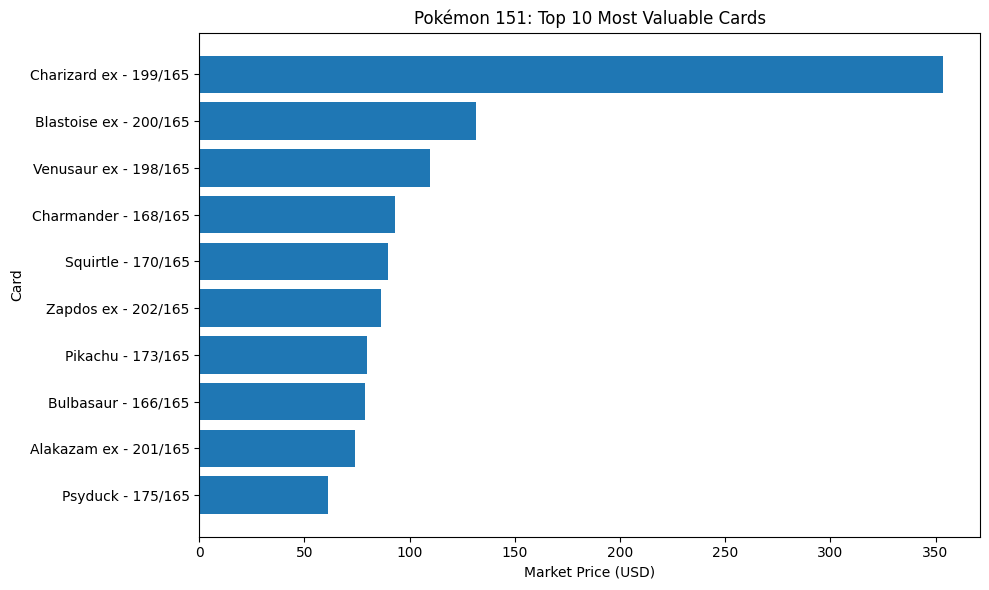

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_10["name"].iloc[::-1],
    top_10["marketPrice"].iloc[::-1]
)

plt.xlabel("Market Price (USD)")
plt.ylabel("Card")
plt.title("Pokémon 151: Top 10 Most Valuable Cards")

plt.tight_layout()
plt.show()

In [ ]:
variant_counts = (
    cards_clean
    .groupby(["extRarity", "subTypeName"])
    .size()
    .unstack(fill_value=0)
)

variant_counts

subTypeName,Holofoil,Normal,Reverse Holofoil
extRarity,,,
Common,0,66,66
Double Rare,12,1,0
Hyper Rare,3,0,0
Illustration Rare,16,0,0
Rare,25,0,25
Special Illustration Rare,7,0,0
Ultra Rare,16,0,0
Uncommon,0,62,62


In [ ]:
variant_analysis = (
    cards_clean
    .groupby(["extRarity", "subTypeName"])["marketPrice"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

variant_analysis

,extRarity,subTypeName,count,mean,median,min,max
0,Common,Normal,66,0.189545,0.175,0.09,0.36
1,Common,Reverse Holofoil,66,0.647727,0.310,0.21,3.11
2,Double Rare,Holofoil,12,2.595000,1.610,1.00,8.79
3,Double Rare,Normal,1,22.860000,22.860,22.86,22.86
4,Hyper Rare,Holofoil,3,11.510000,4.350,2.37,27.81
5,Illustration Rare,Holofoil,16,46.694375,44.370,13.22,93.05
6,Rare,Holofoil,25,0.597600,0.310,0.23,3.47
7,Rare,Reverse Holofoil,25,1.944000,1.400,0.67,8.89
8,Special Illustration Rare,Holofoil,7,112.145714,86.460,14.85,353.46
9,Ultra Rare,Holofoil,16,11.617500,7.390,2.99,39.32


In [ ]:
variant_median = (
    cards_clean
    .groupby(["extRarity", "subTypeName"])["marketPrice"]
    .median()
    .unstack()
)

variant_median

subTypeName,Holofoil,Normal,Reverse Holofoil
extRarity,,,
Common,NaN,0.175,0.310
Double Rare,1.61,22.860,NaN
Hyper Rare,4.35,NaN,NaN
Illustration Rare,44.37,NaN,NaN
Rare,0.31,NaN,1.400
Special Illustration Rare,86.46,NaN,NaN
Ultra Rare,7.39,NaN,NaN
Uncommon,NaN,0.195,0.345
